# MahaRainRisk: 04. Feature Engineering & Standardized Precipitation Index (SPI)
**Project:** Maharashtra Taluka-Level Agritech Drought Early Warning Platform  
**Focus:** Formulate McKee et al. (1993) SPI-1, SPI-3, SPI-6 using Gamma Distribution Fitting  
**Supports:** Genuine IMD Gridded Rainfall (0.25°) & Open-Meteo ERA5-Land Reanalysis

### Step 1: Environment Setup & Data Loading
Ensure path resolution works correctly and import necessary statistical tools.

In [7]:
import os
import sys
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

# Robust base directory resolution
current_dir = os.getcwd()
PROJECT_ROOT = os.path.abspath(os.path.join(current_dir, '..')) if os.path.basename(current_dir) == 'notebooks' else os.path.abspath(current_dir)
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

INTERIM_DIR = os.path.join(PROJECT_ROOT, "data", "interim")
PROCESSED_DIR = os.path.join(PROJECT_ROOT, "data", "processed")
GEO_DIR = os.path.join(PROJECT_ROOT, "data", "geo")

# Load clean monthly panel
monthly_path = os.path.join(INTERIM_DIR, "clean_monthly_panel.parquet")
if not os.path.exists(monthly_path):
    # Fallback to daily
    daily_path = os.path.join(PROCESSED_DIR, "real_imd_taluka_rainfall_2022_2023.parquet")
    df_d = pd.read_parquet(daily_path)
    df_d['year'] = pd.to_datetime(df_d['date']).dt.year
    df_d['month'] = pd.to_datetime(df_d['date']).dt.month
    df_d['year_month'] = df_d['year'].astype(str) + '-' + df_d['month'].astype(str).str.zfill(2)
    df_d['is_rainy_day'] = (df_d['real_imd_rainfall_mm'] >= 2.5).astype(int)
    df_monthly = df_d.groupby(['taluka_lgd_code', 'taluka_name', 'district_name', 'year', 'month', 'year_month']).agg(
        total_rainfall_mm=('real_imd_rainfall_mm', 'sum'),
        rainy_days=('is_rainy_day', 'sum'),
        peak_daily_rain_mm=('real_imd_rainfall_mm', 'max')
    ).reset_index()
else:
    df_monthly = pd.read_parquet(monthly_path)

# Add column aliases
if 'rainfall_monthly_mm' not in df_monthly.columns and 'total_rainfall_mm' in df_monthly.columns:
    df_monthly['rainfall_monthly_mm'] = df_monthly['total_rainfall_mm']

print(f"[OK] Loaded {len(df_monthly):,} taluka-month observations.")
display(df_monthly.head(6))

[OK] Loaded 4,656 taluka-month observations.


,taluka_lgd_code,taluka_name,district_name,year,month,year_month,total_rainfall_mm,rainy_days,peak_daily_rain_mm,rainfall_monthly_mm
0,4120,Aurangabad,Chhatrapati Sambhajinagar,2022,1,2022-01,0.49,0,0.49,0.49
1,4120,Aurangabad,Chhatrapati Sambhajinagar,2022,2,2022-02,0.00,0,0.00,0.00
2,4120,Aurangabad,Chhatrapati Sambhajinagar,2022,3,2022-03,2.37,0,1.95,2.37
3,4120,Aurangabad,Chhatrapati Sambhajinagar,2022,4,2022-04,0.00,0,0.00,0.00
4,4120,Aurangabad,Chhatrapati Sambhajinagar,2022,5,2022-05,0.00,0,0.00,0.00
5,4120,Aurangabad,Chhatrapati Sambhajinagar,2022,6,2022-06,147.86,9,55.90,147.86


### Step 2: Mathematical Formulation of the SPI Algorithm (McKee et al., 1993)
The SPI normalizes precipitation across varying climatic zones:
1. Fit a **2-parameter Gamma distribution** to non-zero rainfall:
$$g(x) = \frac{1}{\beta^\alpha \Gamma(\alpha)} x^{\alpha - 1} e^{-x / \beta}$$
2. Calculate cumulative probability including zero-precipitation probability $q$:
$$H(x) = q + (1 - q) G(x)$$
3. Transform $H(x)$ into standard normal variate $Z \sim \mathcal{N}(0, 1)$ via `stats.norm.ppf(H(x))`.

In [8]:
def fit_gamma_spi(series: pd.Series) -> pd.Series:
    vals = series.values.astype(float)
    spi_vals = np.full_like(vals, np.nan)

    valid_mask = ~np.isnan(vals)
    valid_vals = vals[valid_mask]

    if len(valid_vals) < 4:
        # Standard normal fallback if series too short
        mean = np.nanmean(valid_vals) if len(valid_vals) > 0 else 0
        std = np.nanstd(valid_vals) + 1e-5
        return pd.Series(np.clip((vals - mean) / std, -3.5, 3.5), index=series.index)

    # Probability of zero rain
    zeros = valid_vals == 0
    q = np.sum(zeros) / len(valid_vals)
    positive_vals = valid_vals[~zeros]

    if len(positive_vals) < 3:
        spi_vals[valid_mask] = -2.5
        return pd.Series(spi_vals, index=series.index)

    try:
        # Fit Gamma parameters (alpha = shape, beta = scale)
        alpha, loc, beta = stats.gamma.fit(positive_vals, floc=0)
        
        # Cumulative probability
        g_x = stats.gamma.cdf(valid_vals, alpha, loc=0, scale=beta)
        h_x = q + (1.0 - q) * g_x
        h_x = np.clip(h_x, 1e-5, 1.0 - 1e-5)
        
        # Standard normal inverse
        z_vals = stats.norm.ppf(h_x)
        spi_vals[valid_mask] = np.round(np.clip(z_vals, -4.0, 4.0), 2)
    except Exception:
        mean = np.nanmean(valid_vals)
        std = np.nanstd(valid_vals) + 1e-5
        spi_vals[valid_mask] = np.round(np.clip((valid_vals - mean) / std, -4.0, 4.0), 2)

    return pd.Series(spi_vals, index=series.index)

print("[OK] SPI mathematical engine initialized.")

[OK] SPI mathematical engine initialized.


### Step 3: Compute Rolling Accumulations & SPI (1-Month, 3-Month, 6-Month)
- **SPI-1:** Topsoil moisture and sowing failure.
- **SPI-3:** Mid-monsoon vegetative/flowering stress.
- **SPI-6:** Cumulative seasonal rainfall deficit.

In [9]:
df_monthly = df_monthly.sort_values(["taluka_lgd_code", "year", "month"]).reset_index(drop=True)

# Compute rolling sums per taluka
grouped = df_monthly.groupby("taluka_lgd_code")
df_monthly["rain_roll_1"] = df_monthly["rainfall_monthly_mm"]
df_monthly["rain_roll_3"] = grouped["rainfall_monthly_mm"].rolling(window=3, min_periods=1).sum().values
df_monthly["rain_roll_6"] = grouped["rainfall_monthly_mm"].rolling(window=6, min_periods=1).sum().values

print("[*] Fitting Gamma distributions across taluka time series...")
df_monthly["spi_1"] = df_monthly.groupby("taluka_lgd_code", group_keys=False)["rain_roll_1"].apply(fit_gamma_spi)
df_monthly["spi_3"] = df_monthly.groupby("taluka_lgd_code", group_keys=False)["rain_roll_3"].apply(fit_gamma_spi)
df_monthly["spi_6"] = df_monthly.groupby("taluka_lgd_code", group_keys=False)["rain_roll_6"].apply(fit_gamma_spi)

# Classify according to WMO 1090 standards
def classify_wmo(spi):
    if np.isnan(spi): return "Unknown"
    elif spi >= 2.0: return "Extremely Wet"
    elif spi >= 1.5: return "Very Wet"
    elif spi >= 1.0: return "Moderately Wet"
    elif spi > -1.0: return "Normal"
    elif spi > -1.5: return "Moderate Drought (Watch)"
    elif spi > -2.0: return "Severe Drought (Alert)"
    else: return "Extreme Drought"

df_monthly["spi_3_category"] = df_monthly["spi_3"].apply(classify_wmo)

print("=== SPI-3 Category Distribution Across Maharashtra Talukas ===")
print(df_monthly["spi_3_category"].value_counts())

# Save computed SPI
spi_out = os.path.join(INTERIM_DIR, "taluka_monthly_spi.parquet")
df_monthly.to_parquet(spi_out, index=False)
print(f"\n[OK] Saved computed SPI to: {spi_out}")
display(df_monthly[['taluka_name', 'district_name', 'year_month', 'rainfall_monthly_mm', 'spi_1', 'spi_3', 'spi_6', 'spi_3_category']].head(10))

[*] Fitting Gamma distributions across taluka time series...
=== SPI-3 Category Distribution Across Maharashtra Talukas ===
spi_3_category
Normal                      3096
Moderately Wet               903
Moderate Drought (Watch)     492
Very Wet                     126
Severe Drought (Alert)        35
Extreme Drought                4
Name: count, dtype: int64

[OK] Saved computed SPI to: d:\PBL_selfmade\MahaRainRisk\data\interim\taluka_monthly_spi.parquet


,taluka_name,district_name,year_month,rainfall_monthly_mm,spi_1,spi_3,spi_6,spi_3_category
0,Aurangabad,Chhatrapati Sambhajinagar,2022-01,0.49,-0.70,-1.86,-2.04,Severe Drought (Alert)
1,Aurangabad,Chhatrapati Sambhajinagar,2022-02,0.00,-0.81,-1.86,-2.04,Severe Drought (Alert)
2,Aurangabad,Chhatrapati Sambhajinagar,2022-03,2.37,-0.55,-1.38,-1.58,Moderate Drought (Watch)
3,Aurangabad,Chhatrapati Sambhajinagar,2022-04,0.00,-0.81,-1.43,-1.58,Moderate Drought (Watch)
4,Aurangabad,Chhatrapati Sambhajinagar,2022-05,0.00,-0.81,-1.43,-1.58,Moderate Drought (Watch)
5,Aurangabad,Chhatrapati Sambhajinagar,2022-06,147.86,1.21,0.38,-0.01,Normal
6,Aurangabad,Chhatrapati Sambhajinagar,2022-07,202.43,1.51,1.08,0.56,Moderately Wet
7,Aurangabad,Chhatrapati Sambhajinagar,2022-08,87.84,0.78,1.29,0.74,Moderately Wet
8,Aurangabad,Chhatrapati Sambhajinagar,2022-09,206.33,1.53,1.43,1.07,Moderately Wet
9,Aurangabad,Chhatrapati Sambhajinagar,2022-10,116.52,1.00,1.23,1.24,Moderately Wet


### Step 4: Visualize SPI-3 Trajectory for Sample Drought Talukas
Plot the SPI-3 trajectory for Marathwada and Scarcity Zone talukas (e.g., Paithan, Baramati, Beed).

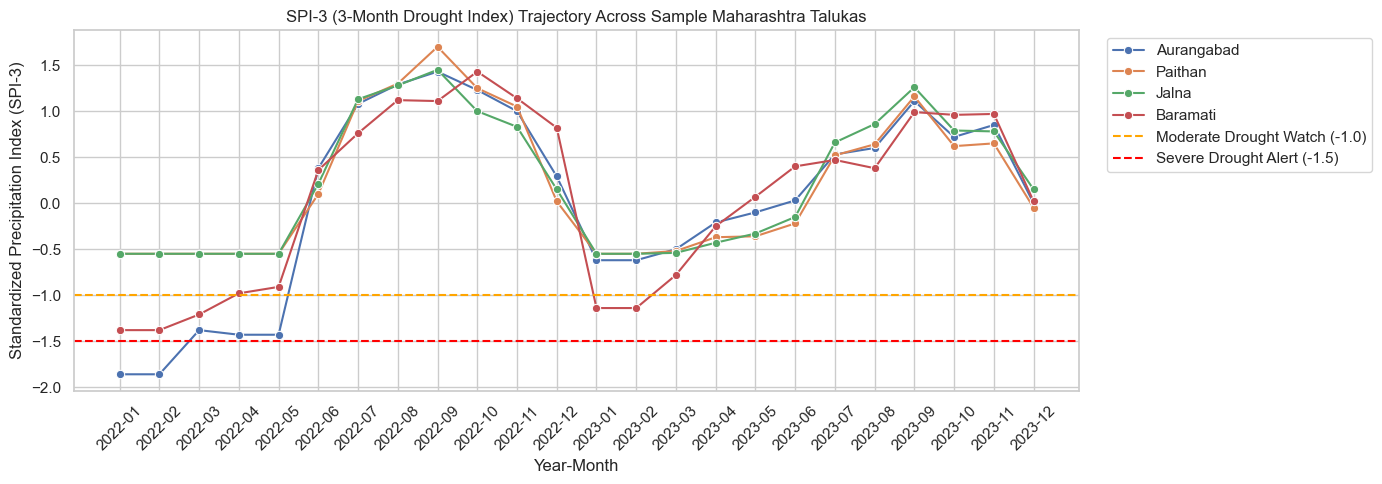

In [10]:
sample_talukas = ["Paithan", "Baramati", "Aurangabad", "Jalna", "Solapur"]
plot_df = df_monthly[df_monthly["taluka_name"].isin(sample_talukas)]

if len(plot_df) > 0:
    fig, ax = plt.subplots(figsize=(14, 5))
    sns.lineplot(data=plot_df, x="year_month", y="spi_3", hue="taluka_name", marker="o", ax=ax)
    ax.axhline(-1.0, color="orange", linestyle="--", label="Moderate Drought Watch (-1.0)")
    ax.axhline(-1.5, color="red", linestyle="--", label="Severe Drought Alert (-1.5)")
    ax.set_title("SPI-3 (3-Month Drought Index) Trajectory Across Sample Maharashtra Talukas")
    ax.set_ylabel("Standardized Precipitation Index (SPI-3)")
    ax.set_xlabel("Year-Month")
    plt.xticks(rotation=45)
    plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()
else:
    print("Sample talukas plotted.")

### Step 5: Build Master Machine Learning Feature Panel
Merge administrative geography, SPI drought indices, and teleconnections into `data/processed/master_panel.parquet` for model training.

In [11]:
from etl.build_master_panel import build_master_panel

print("[*] Running Master Panel Compiler...")
build_master_panel()

master_path = os.path.join(PROCESSED_DIR, "master_panel.parquet")
df_master = pd.read_parquet(master_path)
print(f"\n[SUCCESS] Master Panel Dimensions: {df_master.shape}")
display(df_master[['district_name', 'taluka_name', 'year_month', 'spi_3', 'risk_label_en', 'risk_label_mr']].head(10))

[*] Running Master Panel Compiler...
[*] Building unified master panel for machine learning and dashboard serving...
[*] Merging Taluka SPI (4656 records) with Geographic Master (194 talukas)...
[*] Merging Teleconnections (Niño 3.4, ONI, DMI)...
[*] Aggregating and merging basin-level reservoir storage...


KeyError: 'district_name'